In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
BASE_RESULTS = "/content/drive/MyDrive/Assamese_Sentiment_Analysis/Results/"


# Import the necessary libraries

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import roc_curve, auc
from sklearn.manifold import TSNE

import warnings
warnings.filterwarnings("ignore")

plt.rcParams["figure.figsize"] = (10, 6)


# Load Evaluation Metrics (Central Table)

In [4]:
results = {
    "Model": ["MuRIL", "IndicBERT", "XLM-R", "CNN-BiLSTM", "SVM"],
    "Accuracy": [0.963293, 0.927141, 0.948832, 0.930478, 0.850389],
    "Macro_F1": [0.960526, 0.921967, 0.945181, 0.923780, 0.836560],
    "Precision": [0.960819, 0.920584, 0.943848, 0.934143, 0.843188],
    "Recall": [0.960236, 0.923433, 0.946586, 0.915988, 0.831493],
    "ROC_AUC": [0.988171, 0.977318, 0.985455, 0.978665, 0.931350],
    "Cohen_Kappa": [0.921052, 0.84394, 0.890366, 0.847740, 0.673386]
}

df_results = pd.DataFrame(results)
df_results


,Model,Accuracy,Macro_F1,Precision,Recall,ROC_AUC,Cohen_Kappa
0,MuRIL,0.963293,0.960526,0.960819,0.960236,0.988171,0.921052
1,IndicBERT,0.927141,0.921967,0.920584,0.923433,0.977318,0.843940
2,XLM-R,0.948832,0.945181,0.943848,0.946586,0.985455,0.890366
3,CNN-BiLSTM,0.930478,0.923780,0.934143,0.915988,0.978665,0.847740
4,SVM,0.850389,0.836560,0.843188,0.831493,0.931350,0.673386


# Grouped Bar Chart

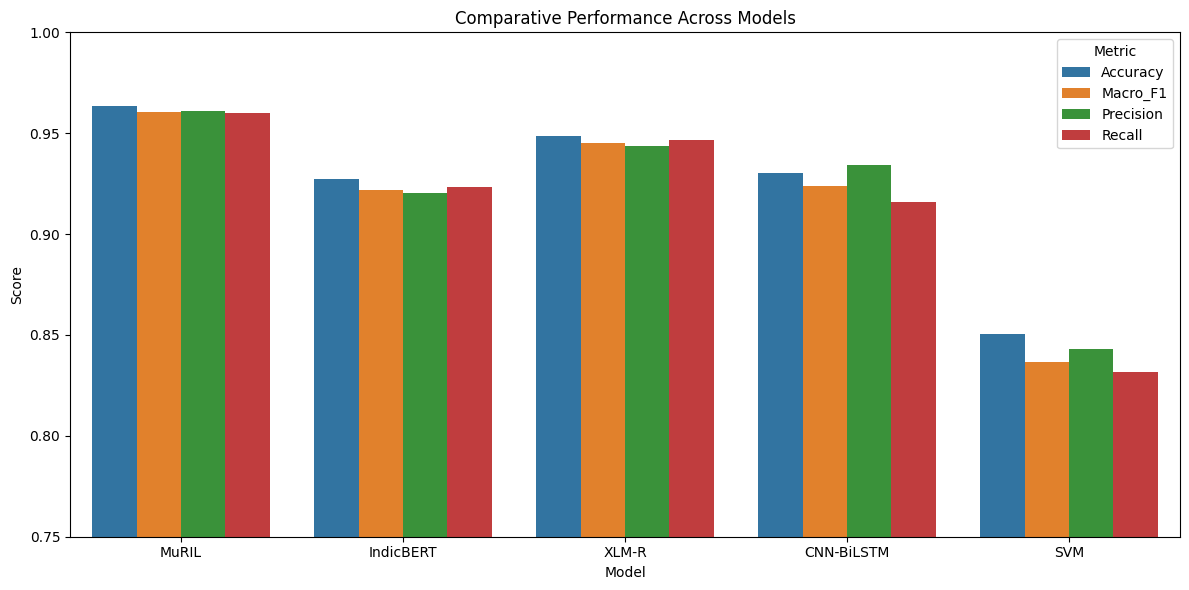

In [5]:
metrics = ["Accuracy", "Macro_F1", "Precision", "Recall"]
df_melted = df_results.melt(id_vars="Model", value_vars=metrics)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=df_melted,
    x="Model",
    y="value",
    hue="variable"
)

plt.ylim(0.75, 1.0)
plt.ylabel("Score")
plt.xlabel("Model")
plt.title("Comparative Performance Across Models")
plt.legend(title="Metric")
plt.tight_layout()

plt.savefig(BASE_RESULTS + "Grouped_Bar_Comparison.svg", format="svg")
plt.show()


# Cohen's Kappa Ranked Bar Chart

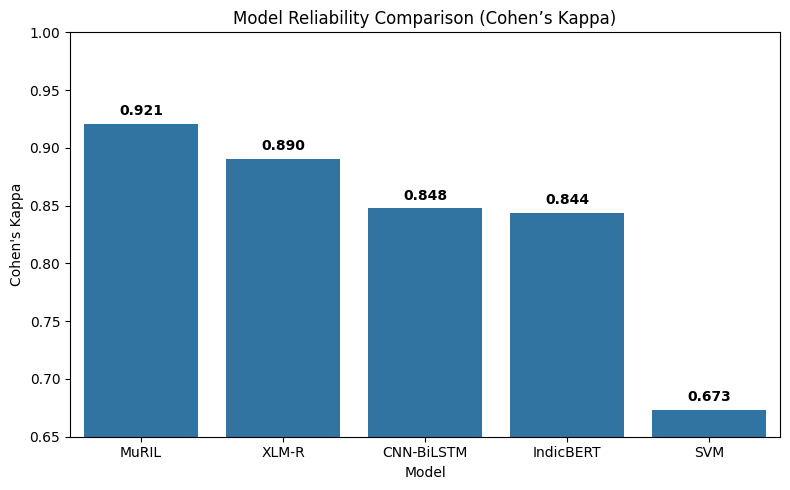

In [13]:
df_sorted = df_results.sort_values("Cohen_Kappa", ascending=False)

plt.figure(figsize=(8, 5))
barplot = sns.barplot(
    data=df_sorted,
    x="Model",
    y="Cohen_Kappa"
)

# Add value labels on top of bars
for p in barplot.patches:
    height = p.get_height()
    barplot.annotate(
        f"{height:.3f}",
        (p.get_x() + p.get_width() / 2., height),
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight="bold",
        xytext=(0, 4),
        textcoords='offset points'
    )

plt.ylim(0.65, 1.0)
plt.ylabel("Cohen's Kappa")
plt.title("Model Reliability Comparison (Cohen’s Kappa)")
plt.tight_layout()

plt.savefig(BASE_RESULTS + "Cohen_Kappa_Comparison.svg", format="svg")
plt.show()


# ROC-AUC Bar Chart

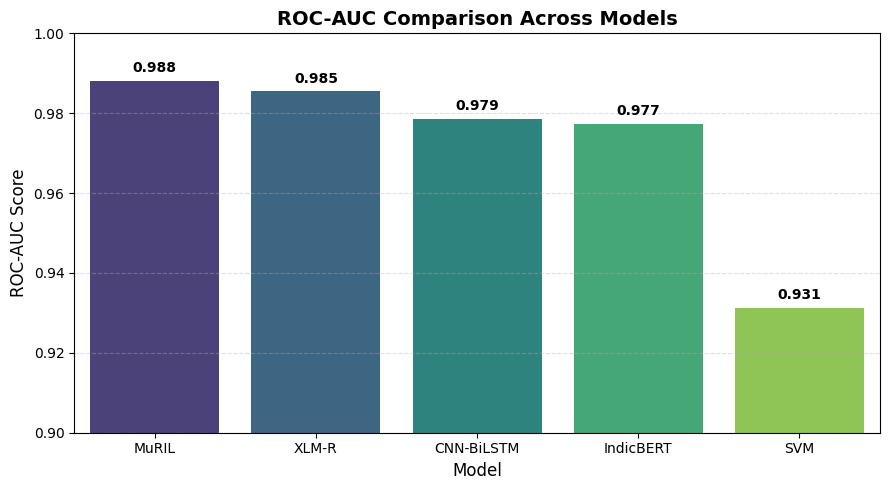

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Sort by ROC-AUC (descending)
df_roc = df_results.sort_values("ROC_AUC", ascending=False)

plt.figure(figsize=(9, 5))

barplot = sns.barplot(
    data=df_roc,
    x="Model",
    y="ROC_AUC",
    palette="viridis"
)

# Add value labels on top of bars
for p in barplot.patches:
    height = p.get_height()
    barplot.annotate(
        f"{height:.3f}",
        (p.get_x() + p.get_width() / 2., height),
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight="bold",
        xytext=(0, 4),
        textcoords='offset points'
    )

plt.ylim(0.90, 1.00)
plt.ylabel("ROC-AUC Score", fontsize=12)
plt.xlabel("Model", fontsize=12)
plt.title("ROC-AUC Comparison Across Models", fontsize=14, fontweight="bold")

plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()

plt.savefig(
    BASE_RESULTS + "ROC_AUC_Bar_Comparison.svg",
    format="svg",
    dpi=300
)

plt.show()


# ROC-AUC vs Accuracy Scatter Plot

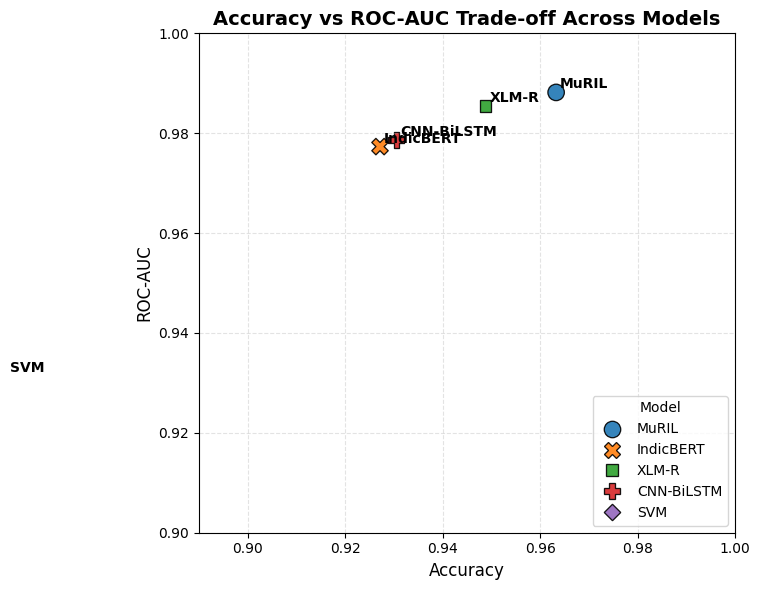

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))

# Base scatter plot
scatter = sns.scatterplot(
    data=df_results,
    x="Accuracy",
    y="ROC_AUC",
    hue="Model",
    style="Model",
    s=140,
    palette="tab10",
    edgecolor="black",
    alpha=0.9
)

# Annotate each point with model name
for _, row in df_results.iterrows():
    plt.text(
        row["Accuracy"] + 0.0008,
        row["ROC_AUC"] + 0.0008,
        row["Model"],
        fontsize=10,
        weight="bold"
    )

plt.xlabel("Accuracy", fontsize=12)
plt.ylabel("ROC-AUC", fontsize=12)
plt.title(
    "Accuracy vs ROC-AUC Trade-off Across Models",
    fontsize=14,
    fontweight="bold"
)

plt.xlim(0.89, 1.0)
plt.ylim(0.90, 1.0)

plt.grid(True, linestyle="--", alpha=0.35)
plt.legend(title="Model", loc="lower right", frameon=True)

plt.tight_layout()

plt.savefig(
    BASE_RESULTS + "Accuracy_vs_ROCAUC_Scatter.svg",
    format="svg",
    dpi=300
)

plt.show()


# Metric Correlation Heatmap

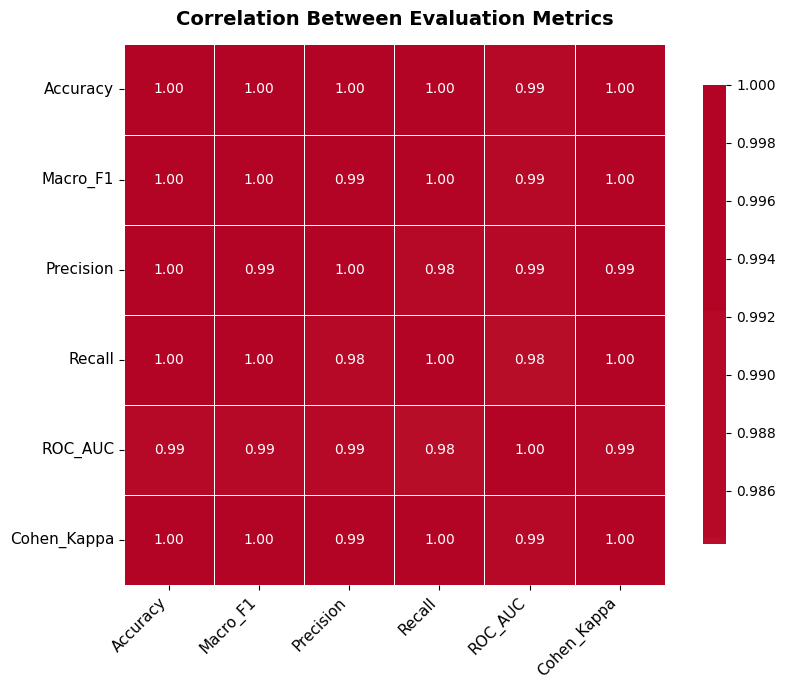

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select only numeric metric columns
metric_cols = [
    "Accuracy",
    "Macro_F1",
    "Precision",
    "Recall",
    "ROC_AUC",
    "Cohen_Kappa"
]

corr_matrix = df_results[metric_cols].corr()

plt.figure(figsize=(9, 7))

heatmap = sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.6,
    linecolor="white",
    square=True,
    cbar_kws={"shrink": 0.85}
)

plt.title(
    "Correlation Between Evaluation Metrics",
    fontsize=14,
    fontweight="bold",
    pad=14
)

plt.xticks(rotation=45, ha="right", fontsize=11)
plt.yticks(rotation=0, fontsize=11)

plt.tight_layout()

plt.savefig(
    BASE_RESULTS + "Metric_Correlation_Heatmap.svg",
    format="svg",
    dpi=300
)

plt.show()


# Radar Chart (Transfer Learning Emphasis)

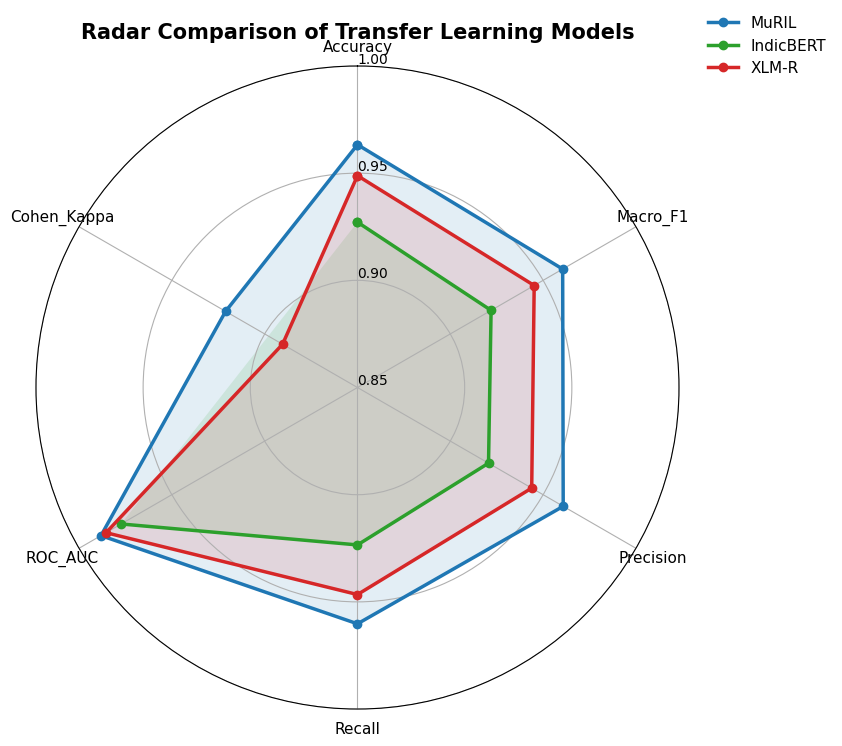

In [11]:
import numpy as np
import matplotlib.pyplot as plt

# Models and metrics to compare
radar_models = ["MuRIL", "IndicBERT", "XLM-R"]
radar_metrics = ["Accuracy", "Macro_F1", "Precision", "Recall", "ROC_AUC", "Cohen_Kappa"]

# Prepare angles
num_metrics = len(radar_metrics)
angles = np.linspace(0, 2 * np.pi, num_metrics, endpoint=False).tolist()
angles += angles[:1]

# Initialize figure
fig, ax = plt.subplots(figsize=(8.5, 8.5), subplot_kw=dict(polar=True))

# Styling
ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)

# Axis labels
ax.set_thetagrids(np.degrees(angles[:-1]), radar_metrics, fontsize=11)
ax.set_rlabel_position(0)
ax.set_yticks([0.85, 0.90, 0.95, 1.00])
ax.set_yticklabels(["0.85", "0.90", "0.95", "1.00"], fontsize=10)
ax.set_ylim(0.85, 1.00)

# Color palette (color-blind friendly)
colors = ["#1f77b4", "#2ca02c", "#d62728"]

# Plot each model
for model, color in zip(radar_models, colors):
    values = (
        df_results[df_results["Model"] == model][radar_metrics]
        .values.flatten()
        .tolist()
    )
    values += values[:1]

    ax.plot(
        angles,
        values,
        linewidth=2.5,
        linestyle="-",
        marker="o",
        label=model,
        color=color
    )
    ax.fill(
        angles,
        values,
        color=color,
        alpha=0.12
    )

# Title and legend
plt.title(
    "Radar Comparison of Transfer Learning Models",
    fontsize=15,
    fontweight="bold",
    pad=20
)

ax.legend(
    loc="upper right",
    bbox_to_anchor=(1.25, 1.10),
    frameon=False,
    fontsize=11
)

plt.tight_layout()

# Save as SVG
plt.savefig(
    BASE_RESULTS + "Radar_Transfer_Learning.svg",
    format="svg",
    dpi=300
)

plt.show()


# Save Best Model Automatically

In [12]:
best_model_name = df_results.sort_values("Macro_F1", ascending=False).iloc[0]["Model"]
print("Best Model:", best_model_name)


Best Model: MuRIL
